In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')

project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *

2024-06-24 17:31:10.553312: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-06-24 17:31:10.616731: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-06-24 17:31:10.616769: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-06-24 17:31:10.618376: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-06-24 17:31:10.627235: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-06-24 17:31:10.627900: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [ ]:
K_array = np.array([1,2,4,8])
N_K = len(K_array)

data = []
for i in range(N_K):
    load_path = project_folder + f'/analyses/multiplexed prediction/saved/opticflow/longer training (1,B,1) K={K_array[i]}.dat'
    with open(load_path, 'rb') as f:
        data_dict = pickle.load(f)
    data.append(Namespace(**data_dict))

load_path = load_path = project_folder + f'/analyses/multiplexed prediction/saved/opticflow/head start bound.dat'
with open(load_path, 'rb') as f:
    data_dict_bound = pickle.load(f)
data_bound = Namespace(**data_dict_bound)

In [4]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, stdevs

average_test = []
stdevs_test = []
for i in range(N_K):
    a, b = process_trials(data[i].mi_averages_test, data[i].mi_stdevs_test)
    average_test.append(a)
    stdevs_test.append(b)
    # average_train, stdevs_train = process_trials(data.mi_averages_train, data.mi_stdevs_train)

average_test_bound, stdevs_test_bound = process_trials(data_bound.mi_averages_test, data_bound.mi_stdevs_test)
# average_test_bound, stdevs_test_bound = process_trials(data[0].mi_bound_averages_test, data[0].mi_bound_stdevs_test)

average_test = np.stack(average_test)
stdevs_test = np.stack(stdevs_test) 
average_test[0].shape

(6, 16)

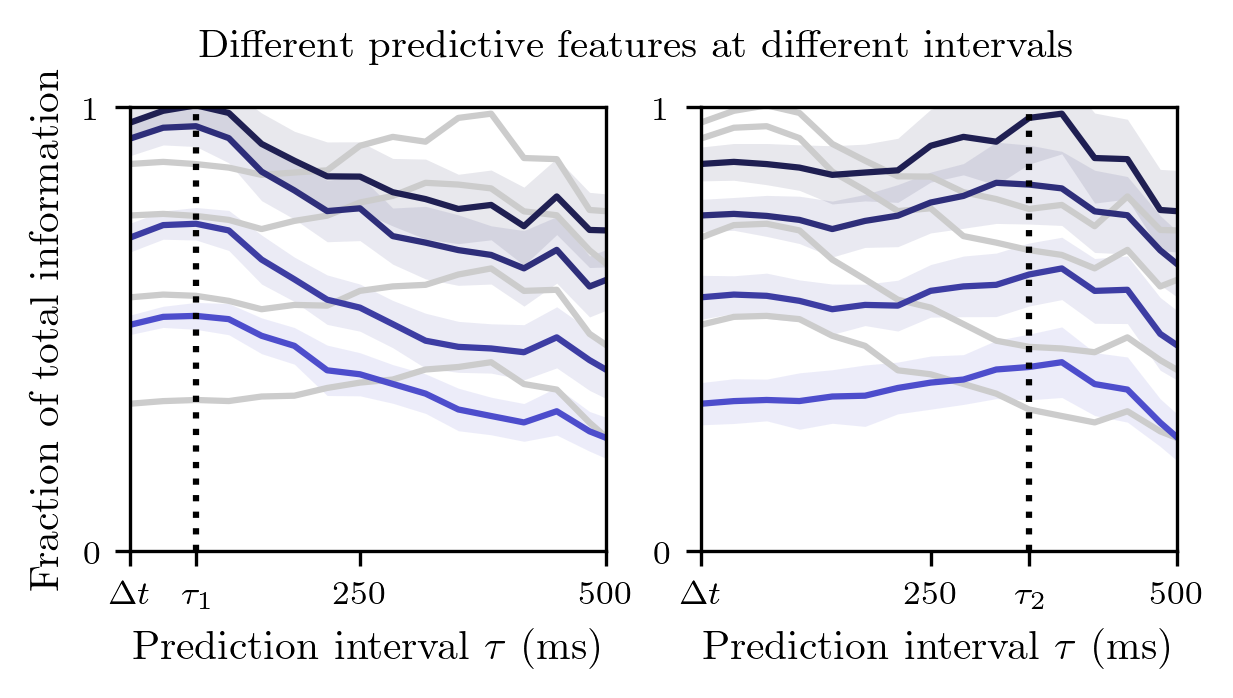

In [ ]:
c1 = 0.3
c2 = 0.8
alp = 0.1
reference_time_inds = [1,5]
binsize = 1000 / 60
colors = [
    (c1,c1,c2),
    # (c1,c2,c1)
    (c1,c1,c2)
]
off_color = (0.8,0.8,0.8)
light = np.linspace(0.6,1,4)[::-1]

# N_reference_times = len(data.reference_times)
# include_label = [0,1,N_reference_times-1]
dt = 1000/60
x = (data[0].V_E_buffer_array + data[0].E_width) * binsize
reference_times = (data[0].reference_times + data[0].E_width) * binsize

fig, ax = plt.subplots(ncols=2, figsize=[9*plot_scale,4*plot_scale], dpi=300)


for j in range(N_K):
    y = average_test[j,reference_time_inds[0],:] / average_test_bound
    ax[1].plot(x, y, color=off_color)
    y = average_test[j,reference_time_inds[1],:] / average_test_bound
    ax[0].plot(x, y, color=off_color)

for i in [0,1]:
    ind = reference_time_inds[i]
    for j in range(N_K):
        K = K_array[j]
        l = (N_K - j + 1) / (N_K + 1)
        # l = light[j]
        cur_color = tuple([a*l for a in colors[i]])
        # cur_color = colors[i]

        y = average_test[j,ind,:] / average_test_bound
        yerr = np.sqrt(
            (stdevs_test[j,ind,:] / average_test_bound)**2 + 
            (stdevs_test_bound * average_test[j,ind,:] / average_test_bound ** 2)**2
        )
        # ax[1].plot(x, y, color=off_color)
        ax[i].fill_between(x, y - yerr, y + yerr, color = cur_color + (alp,), linewidth=0)
        ax[i].plot(x, y, color=cur_color, label=f'$K={K}$')
        ax[i].set_xlabel(r"Prediction interval $\tau$ (ms)")
    ax[i].axvline(reference_times[ind], linestyle=':', color=(0,0,0))
    ax[i].set_xlim(x[0], 500)
    ax[i].set_xticks([dt, 250, 500, reference_times[ind]])
    ax[i].set_xticklabels(["$\Delta t$", 250, 500, f"$\\tau_{i+1}$"])
    ax[i].set_ylim(0,1)
    ax[i].set_yticks([0,1])
    handles, labels = ax[i].get_legend_handles_labels()
    # ax[i].legend(handles[::-1], labels[::-1], loc='lower left')


ax[0].set_ylabel('Fraction of predictive information')
fig.suptitle(r"Different predictive features at different intervals")
fig.subplots_adjust(top=0.85)

# plt.savefig("./plots/multiplexing.png", dpi=3000)